# Phase 3D — Controlled XGBoost Comparison

Goal:
Compare the Phase 2 chemistry-aware model with the Phase 3 descriptor-enhanced model using identical rows, splits, targets, and XGBoost settings.

Question:
Do Phase 3 descriptors add predictive value beyond geometry + linker descriptors?
## 1. Load Dataset
- Load the Phase 3 final descriptor dataset.
- Check shape, columns, and missing values.

## 2. Define Feature Sets
- Model A: geometry + linker descriptors.
- Model B: geometry + linker descriptors + Phase 3 descriptors.

## 3. Define Targets
- CO2 uptake at 0.01, 0.05, 0.1, 0.5, and 2.5 bar.

## 4. Create Identical Rows
- Drop rows with missing values required for either model.
- Use the same filtered dataframe for both models.

## 5. Create Identical Splits
- Train/validation/test split once.
- Reuse the same indices for Model A and Model B.

## 6. Train Controlled XGBoost Models
- Use identical model settings.
- Train Model A and Model B for each pressure.

## 7. Compare Metrics
- MAE
- RMSE
- R²

## 8. Quantify Improvement
- MAE reduction %
- RMSE reduction %
- R² increase

## 9. Scientific Summary
- Decide whether Phase 3 descriptors add predictive value.

In [ ]:
import sys
from pathlib import Path

# Add the project root so the shared path configuration is importable.
PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src" / "paths.py").is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.paths import DATA_DIR, MODELS_DIR, RAW_DATA_DIR, RESULTS_DIR, RESULTS_ROOT


In [1]:
# Import libraries needed for controlled train/validation/test splitting and model evaluation.
import random
import numpy as np
import pandas as pd
import re 
import os
from pathlib import Path
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

SEED = 12345

random.seed(SEED)
np.random.seed(SEED)

In [2]:
# Load the Phase 3 final descriptor dataset.
# This dataset contains the CIF-matched MOFs plus Phase 3 descriptor columns.
# low_memory=False prevents pandas from guessing column types in small chunks.

phase3_xgboost_path = Path(
    DATA_DIR / "hmof_phase3_structure_descriptors.csv"
)

df = pd.read_csv(phase3_xgboost_path, low_memory=False)

print(df.shape)
print()
print("The Phase 3c dataset was loaded successfully\n with 25,928 MOFs and 75 columns.")
print("=" * 30)

(25928, 75)

The Phase 3c dataset was loaded successfully
 with 25,928 MOFs and 75 columns.


In [3]:
# Check all column names so we can separate targets, identifiers, Phase 2 features, and Phase 3 features.
df.columns.tolist()



['filename',
 'lcd',
 'pld',
 'void_fraction',
 'surface_area_m2g',
 'mofid',
 'CO2_uptake_0.01bar_molkg',
 'CO2_uptake_0.05bar_molkg',
 'CO2_uptake_0.1bar_molkg',
 'CO2_uptake_0.5bar_molkg',
 'CO2_uptake_2.5bar_molkg',
 'chemical_representation',
 'linker_smiles',
 'invalid_fragments',
 'linker_1',
 'linker_2',
 'linker_3',
 'linker_4',
 'linker_5',
 'linker_6',
 'linker_7',
 'linker_8',
 'linker_9',
 'linker_10',
 'linker_11',
 'linker_12',
 'linker_13',
 'total_C_count',
 'total_N_count',
 'total_O_count',
 'total_F_count',
 'total_S_count',
 'total_Cl_count',
 'total_Br_count',
 'total_I_count',
 'total_heteroatom_count',
 'total_heavy_atom_count',
 'heteroatom_fraction',
 'total_amine_count',
 'total_hydroxyl_count',
 'total_carboxylate_or_carboxylic_acid_count',
 'total_fluorinated_group_count',
 'total_sulfonyl_or_sulfate_count',
 'total_MolWt',
 'mean_MolWt',
 'max_MolWt',
 'total_TPSA',
 'mean_TPSA',
 'max_TPSA',
 'total_HBD',
 'total_HBA',
 'total_aromatic_atom_count',
 'mean

In [4]:
# Define the five CO2 uptake target columns used for controlled model comparison.
target_cols = [
    "CO2_uptake_0.01bar_molkg",
    "CO2_uptake_0.05bar_molkg",
    "CO2_uptake_0.1bar_molkg",
    "CO2_uptake_0.5bar_molkg",
    "CO2_uptake_2.5bar_molkg",
]

df[target_cols].head()

,CO2_uptake_0.01bar_molkg,CO2_uptake_0.05bar_molkg,CO2_uptake_0.1bar_molkg,CO2_uptake_0.5bar_molkg,CO2_uptake_2.5bar_molkg
0,0.022406,0.073552,0.225851,0.885221,4.33307
1,0.173407,0.925813,1.806490,4.779010,7.34618
2,0.651164,2.129830,2.817220,3.909470,4.93236
3,0.031321,0.143123,0.332034,1.756380,6.91190
4,0.144024,0.698367,1.402230,2.694200,4.15694


In [5]:
extend_linker_path = DATA_DIR / 'hmof_linker_extended_descriptors.csv'
df_extended_linker =pd.read_csv(extend_linker_path, low_memory =False)
df_extended_linker.columns.tolist()

['filename',
 'lcd',
 'pld',
 'void_fraction',
 'surface_area_m2g',
 'mofid',
 'CO2_uptake_0.01bar_molkg',
 'CO2_uptake_0.05bar_molkg',
 'CO2_uptake_0.1bar_molkg',
 'CO2_uptake_0.5bar_molkg',
 'CO2_uptake_2.5bar_molkg',
 'chemical_representation',
 'linker_smiles',
 'invalid_fragments',
 'linker_1',
 'linker_2',
 'linker_3',
 'linker_4',
 'linker_5',
 'linker_6',
 'linker_7',
 'linker_8',
 'linker_9',
 'linker_10',
 'linker_11',
 'linker_12',
 'linker_13',
 'total_C_count',
 'total_N_count',
 'total_O_count',
 'total_F_count',
 'total_S_count',
 'total_Cl_count',
 'total_Br_count',
 'total_I_count',
 'total_heteroatom_count',
 'total_heavy_atom_count',
 'heteroatom_fraction',
 'total_amine_count',
 'total_hydroxyl_count',
 'total_carboxylate_or_carboxylic_acid_count',
 'total_fluorinated_group_count',
 'total_sulfonyl_or_sulfate_count',
 'total_MolWt',
 'mean_MolWt',
 'max_MolWt',
 'total_TPSA',
 'mean_TPSA',
 'max_TPSA',
 'total_HBD',
 'total_HBA',
 'total_aromatic_atom_count',
 'mean

---

How well does XGBoost predict CO2 uptake using only geometry + Phase 2 linker descriptors, before adding Phase 3 CIF/metal descriptors?

---

In [6]:
# Define the five CO2 uptake target columns.
target_cols = [
    "CO2_uptake_0.01bar_molkg",
    "CO2_uptake_0.05bar_molkg",
    "CO2_uptake_0.1bar_molkg",
    "CO2_uptake_0.5bar_molkg",
    "CO2_uptake_2.5bar_molkg",
]
print( "target:",len(target_cols))
# Define geometry features used in the Phase 2 baseline model.
geometry_features = [
    "lcd",
    "pld",
    "void_fraction",
    "surface_area_m2g",
]

print("Geometry features:", len(geometry_features))

# Define Phase 2 linker descriptor features used in the baseline model.
linker_features = [
    "total_C_count",
    "total_N_count",
    "total_O_count",
    "total_F_count",
    "total_S_count",
    "total_Cl_count",
    "total_Br_count",
    "total_I_count",
    "total_heteroatom_count",
    "total_heavy_atom_count",
    "heteroatom_fraction",
    "total_amine_count",
    "total_hydroxyl_count",
    "total_carboxylate_or_carboxylic_acid_count",
    "total_fluorinated_group_count",
    "total_sulfonyl_or_sulfate_count",
    "total_MolWt",
    "mean_MolWt",
    "max_MolWt",
    "total_TPSA",
    "mean_TPSA",
    "max_TPSA",
    "total_HBD",
    "total_HBA",
    "total_aromatic_atom_count",
    "mean_aromatic_fraction",
    "total_heavy_atom_count_rdkit",
    "total_ring_count",
    "total_rotatable_bond_count",
]

print("Linker descriptor features:", len(linker_features))
print("These features describe linker composition, functional groups, polarity, aromaticity, size, and flexibility.")

target: 5
Geometry features: 4
Linker descriptor features: 29
These features describe linker composition, functional groups, polarity, aromaticity, size, and flexibility.


In [7]:
# Check how many total columns are in the full corrected Phase 3D dataset.
print("Total dataset columns:", df.shape[1])
# Check how many features are used for Model A only.
# Combine geometry and linker descriptors to create Model A baseline features.
model_a_features = geometry_features + linker_features
print("Total Model A features:", len(model_a_features))
print("Model A feature count:", len(model_a_features))
# Print Model A features with index numbers.
for i, feature in enumerate(model_a_features, start=1):
    print(i, feature)

print()
print('Model A contains 33 features: 4 geometry features and 29 Phase 2 extended linker/RDKit descriptor features.')


Total dataset columns: 75
Total Model A features: 33
Model A feature count: 33
1 lcd
2 pld
3 void_fraction
4 surface_area_m2g
5 total_C_count
6 total_N_count
7 total_O_count
8 total_F_count
9 total_S_count
10 total_Cl_count
11 total_Br_count
12 total_I_count
13 total_heteroatom_count
14 total_heavy_atom_count
15 heteroatom_fraction
16 total_amine_count
17 total_hydroxyl_count
18 total_carboxylate_or_carboxylic_acid_count
19 total_fluorinated_group_count
20 total_sulfonyl_or_sulfate_count
21 total_MolWt
22 mean_MolWt
23 max_MolWt
24 total_TPSA
25 mean_TPSA
26 max_TPSA
27 total_HBD
28 total_HBA
29 total_aromatic_atom_count
30 mean_aromatic_fraction
31 total_heavy_atom_count_rdkit
32 total_ring_count
33 total_rotatable_bond_count

Model A contains 33 features: 4 geometry features and 29 Phase 2 extended linker/RDKit descriptor features.


In [8]:
# Split the corrected Phase 3D dataset once so Model A and Model B use identical rows.
# First split: 60% train and 40% temporary data.

df_train, df_temp = train_test_split(
    df,
    test_size=0.40,
    random_state=SEED,
)
print()
print('The dataset is split into 60% training data and 40% temporary data.')
# Split the temporary data into validation and test sets.
# This gives 20% validation and 20% test data.

df_valid, df_test = train_test_split(
    df_temp,
    test_size=0.50,
    random_state=SEED,
)

print("Train:", df_train.shape)
print("Validation:", df_valid.shape)
print("Test:", df_test.shape)
print()
print('The final split is 60% train, 20% validation, and 20% test.')

# Create Model A input matrices using geometry + Phase 2 linker descriptor features.

X_train_a = df_train[model_a_features]
X_valid_a = df_valid[model_a_features]
X_test_a = df_test[model_a_features]

y_train = df_train[target_cols]
y_valid = df_valid[target_cols]
y_test = df_test[target_cols]

print("Model A train input:", X_train_a.shape)
print("Model A validation input:", X_valid_a.shape)
print("Model A test input:", X_test_a.shape)
print("Train targets:", y_train.shape)



The dataset is split into 60% training data and 40% temporary data.
Train: (15556, 75)
Validation: (5186, 75)
Test: (5186, 75)

The final split is 60% train, 20% validation, and 20% test.
Model A train input: (15556, 33)
Model A validation input: (5186, 33)
Model A test input: (5186, 33)
Train targets: (15556, 5)


In [9]:
# Train Model A using the same XGBoost settings used in Phase 2.
# Model A uses geometry + Phase 2 extended linker/RDKit descriptors.
print('Model A uses the Phase 2 baseline feature set and the same XGBoost settings from Phase 2, so it can be fairly compared with Model B later.')
results_model_a = []

for target in target_cols:

    model_xgb_a = XGBRegressor(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=3,
        min_child_weight=1,
        objective="reg:squarederror",
        random_state=SEED,
        n_jobs=-1,
    )

    # Train the model using Model A features.
    model_xgb_a.fit(X_train_a, df_train[target])

    # Predict uptake for training and validation rows.
    train_pred = model_xgb_a.predict(X_train_a)
    valid_pred = model_xgb_a.predict(X_valid_a)

    # Calculate metrics and store results for this pressure.
    results_model_a.append({
        "model": "Model A",
        "pressure": target,
        "train_MAE": mean_absolute_error(df_train[target], train_pred),
        "valid_MAE": mean_absolute_error(df_valid[target], valid_pred),
        "train_RMSE": np.sqrt(mean_squared_error(df_train[target], train_pred)),
        "valid_RMSE": np.sqrt(mean_squared_error(df_valid[target], valid_pred)),
        "train_R2": r2_score(df_train[target], train_pred),
        "valid_R2": r2_score(df_valid[target], valid_pred),
    })

results_model_a = pd.DataFrame(results_model_a)

display(results_model_a.round(4))

Model A uses the Phase 2 baseline feature set and the same XGBoost settings from Phase 2, so it can be fairly compared with Model B later.


,model,pressure,train_MAE,valid_MAE,train_RMSE,valid_RMSE,train_R2,valid_R2
0,Model A,CO2_uptake_0.01bar_molkg,0.0490,0.0553,0.1063,0.1242,0.7606,0.6841
1,Model A,CO2_uptake_0.05bar_molkg,0.1268,0.1389,0.2190,0.2477,0.8255,0.7917
2,Model A,CO2_uptake_0.1bar_molkg,0.1844,0.1985,0.2922,0.3238,0.8441,0.8189
3,Model A,CO2_uptake_0.5bar_molkg,0.3752,0.3937,0.5189,0.5447,0.8752,0.8634
4,Model A,CO2_uptake_2.5bar_molkg,0.6303,0.6630,0.8408,0.8843,0.8965,0.8793


----
Model A was trained successfully using geometry plus Phase 2 extended linker/RDKit descriptors. Validation performance improved with increasing CO2 pressure, with R² increasing from 0.6841 at 0.01 bar to 0.8793 at 2.5 bar. This Model A table is the controlled Phase 2 baseline for comparison with the Phase 3 descriptor-enhanced model.

----

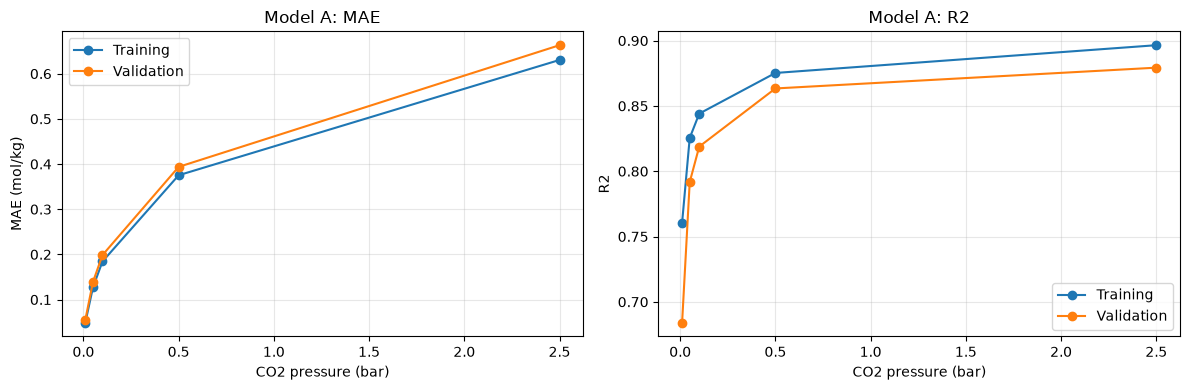

In [10]:
# Check overfitting for Model A by comparing training and validation MAE/R2.
# Model A uses geometry + Phase 2 linker descriptors.

import matplotlib.pyplot as plt
pressures = [0.01, 0.05, 0.1, 0.5, 2.5]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# MAE: lower is better.
axes[0].plot(
    pressures,
    results_model_a["train_MAE"],
    marker="o",
    label="Training"
)

axes[0].plot(
    pressures,
    results_model_a["valid_MAE"],
    marker="o",
    label="Validation"
)

axes[0].set_title("Model A: MAE")
axes[0].set_xlabel("CO2 pressure (bar)")
axes[0].set_ylabel("MAE (mol/kg)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# R2: higher is better.
axes[1].plot(
    pressures,
    results_model_a["train_R2"],
    marker="o",
    label="Training"
)

axes[1].plot(
    pressures,
    results_model_a["valid_R2"],
    marker="o",
    label="Validation"
)

axes[1].set_title("Model A: R2")
axes[1].set_xlabel("CO2 pressure (bar)")
axes[1].set_ylabel("R2")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

For Model A, the training and validation curves follow similar trends across all five CO2 pressures. Validation MAE is slightly higher than training MAE, and validation R² is slightly lower than training R², which is expected. The train-validation gap is moderate rather than large, suggesting that Model A does not show severe overfitting.

In [11]:
# Define Phase 3 CIF-derived metal and structure descriptor features.
phase3_features = [
    "num_metal_types",
    "total_metal_atoms",
    "total_atoms",
    "metal_fraction",
    "avg_metal_atomic_number",
    "avg_metal_atomic_mass",
    "unit_cell_volume",
    "density",
    "num_sites",
    "lattice_a",
    "lattice_b",
    "lattice_c",
    "lattice_alpha",
    "lattice_beta",
    "lattice_gamma",
]

print("Number of Phase 3 features:", len(phase3_features))
# Combine Model A features with Phase 3 descriptor features to create Model B.
model_b_features = model_a_features + phase3_features

print("Number of Model B features:", len(model_b_features))

Number of Phase 3 features: 15
Number of Model B features: 48


---
Model B contains 48 total features: the 33 Model A features plus 15 Phase 3 CIF-derived descriptors. These 15 added descriptors describe metal-node composition, cell size, density, number of sites, and lattice geometry.

---


In [12]:
# Create Model B input matrices using the same train/validation/test rows.
# Model B uses Model A features plus Phase 3 CIF-derived descriptors.

X_train_b = df_train[model_b_features]
X_valid_b = df_valid[model_b_features]
X_test_b = df_test[model_b_features]

print("Model B train input:", X_train_b.shape)
print("Model B validation input:", X_valid_b.shape)
print("Model B test input:", X_test_b.shape)
print("Train targets:", y_train.shape)

Model B train input: (15556, 48)
Model B validation input: (5186, 48)
Model B test input: (5186, 48)
Train targets: (15556, 5)


In [13]:
# Train Model B using the same XGBoost settings as Model A.
# The only change is that Model B includes the Phase 3 descriptor features.

results_model_b = []

for target in target_cols:

    model_xgb_b = XGBRegressor(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=3,
        min_child_weight=1,
        objective="reg:squarederror",
        random_state=SEED,
        n_jobs=-1,
    )

    # Train the model using Model B features.
    model_xgb_b.fit(X_train_b, df_train[target])

    # Predict uptake for training and validation rows.
    train_pred = model_xgb_b.predict(X_train_b)
    valid_pred = model_xgb_b.predict(X_valid_b)

    # Calculate metrics and store results for this pressure.
    results_model_b.append({
        "model": "Model B",
        "pressure": target,
        "train_MAE": mean_absolute_error(df_train[target], train_pred),
        "valid_MAE": mean_absolute_error(df_valid[target], valid_pred),
        "train_RMSE": np.sqrt(mean_squared_error(df_train[target], train_pred)),
        "valid_RMSE": np.sqrt(mean_squared_error(df_valid[target], valid_pred)),
        "train_R2": r2_score(df_train[target], train_pred),
        "valid_R2": r2_score(df_valid[target], valid_pred),
    })

results_model_b = pd.DataFrame(results_model_b)

display(results_model_b.round(4))

,model,pressure,train_MAE,valid_MAE,train_RMSE,valid_RMSE,train_R2,valid_R2
0,Model B,CO2_uptake_0.01bar_molkg,0.0454,0.0522,0.0964,0.1175,0.8032,0.7170
1,Model B,CO2_uptake_0.05bar_molkg,0.1170,0.1312,0.1992,0.2337,0.8555,0.8146
2,Model B,CO2_uptake_0.1bar_molkg,0.1706,0.1878,0.2679,0.3073,0.8689,0.8368
3,Model B,CO2_uptake_0.5bar_molkg,0.3445,0.3668,0.4752,0.5084,0.8954,0.8810
4,Model B,CO2_uptake_2.5bar_molkg,0.5500,0.5832,0.7277,0.7674,0.9225,0.9091


---
Model B was trained successfully using the same rows, same train/validation/test split, and same XGBoost settings as Model A. Adding the 15 Phase 3 CIF-derived descriptors improved validation performance at all five CO2 pressures.

---

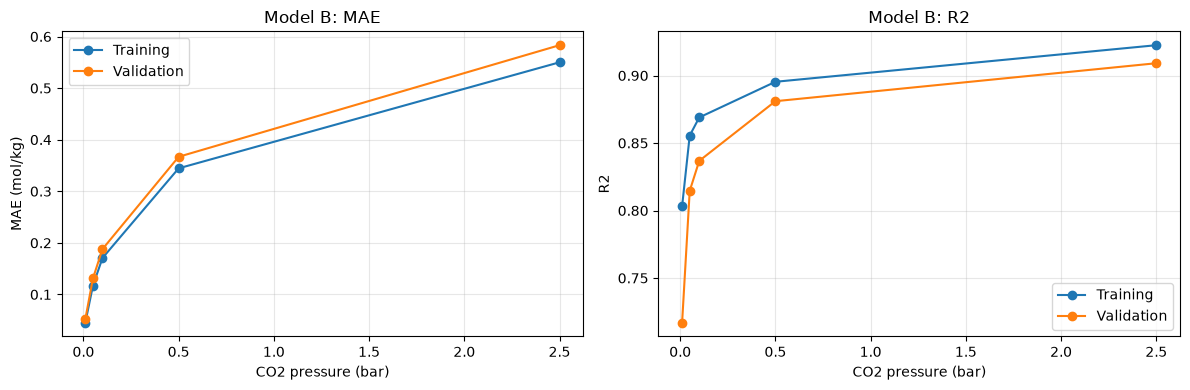

In [14]:
# Check overfitting for Model B by comparing training and validation MAE/R2.
# Model B uses geometry + linker descriptors + Phase 3 CIF-derived descriptors.

pressures = [0.01, 0.05, 0.1, 0.5, 2.5]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Compare training and validation MAE.
axes[0].plot(
    pressures,
    results_model_b["train_MAE"],
    marker="o",
    label="Training"
)

axes[0].plot(
    pressures,
    results_model_b["valid_MAE"],
    marker="o",
    label="Validation"
)

axes[0].set_title("Model B: MAE")
axes[0].set_xlabel("CO2 pressure (bar)")
axes[0].set_ylabel("MAE (mol/kg)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Compare training and validation R2.
axes[1].plot(
    pressures,
    results_model_b["train_R2"],
    marker="o",
    label="Training"
)

axes[1].plot(
    pressures,
    results_model_b["valid_R2"],
    marker="o",
    label="Validation"
)

axes[1].set_title("Model B: R2")
axes[1].set_xlabel("CO2 pressure (bar)")
axes[1].set_ylabel("R2")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

---
For Model B, the training and validation curves follow similar trends across all CO2 pressures. Validation MAE is slightly higher than training MAE, and validation R² is slightly lower than training R², which is expected for a supervised model. The train-validation gap remains moderate, suggesting that adding Phase 3 CIF-derived descriptors improves performance without causing severe overfitting.

---

In [15]:
# Combine Model A and Model B validation results for direct comparison.
comparison_df = results_model_a.merge(
    results_model_b,
    on="pressure",
    suffixes=("_A", "_B")
)

comparison_df[
    [
        "pressure",
        "valid_MAE_A",
        "valid_MAE_B",
        "valid_RMSE_A",
        "valid_RMSE_B",
        "valid_R2_A",
        "valid_R2_B",
    ]
].round(4)

,pressure,valid_MAE_A,valid_MAE_B,valid_RMSE_A,valid_RMSE_B,valid_R2_A,valid_R2_B
0,CO2_uptake_0.01bar_molkg,0.0553,0.0522,0.1242,0.1175,0.6841,0.7170
1,CO2_uptake_0.05bar_molkg,0.1389,0.1312,0.2477,0.2337,0.7917,0.8146
2,CO2_uptake_0.1bar_molkg,0.1985,0.1878,0.3238,0.3073,0.8189,0.8368
3,CO2_uptake_0.5bar_molkg,0.3937,0.3668,0.5447,0.5084,0.8634,0.8810
4,CO2_uptake_2.5bar_molkg,0.6630,0.5832,0.8843,0.7674,0.8793,0.9091


In [16]:
# Quantify improvement from adding Phase 3 descriptors.
comparison_df["MAE_reduction_%"] = (
    (comparison_df["valid_MAE_A"] - comparison_df["valid_MAE_B"])
    / comparison_df["valid_MAE_A"]
) * 100

comparison_df["RMSE_reduction_%"] = (
    (comparison_df["valid_RMSE_A"] - comparison_df["valid_RMSE_B"])
    / comparison_df["valid_RMSE_A"]
) * 100

comparison_df["R2_increase"] = comparison_df["valid_R2_B"] - comparison_df["valid_R2_A"]

comparison_df[
    [
        "pressure",
        "MAE_reduction_%",
        "RMSE_reduction_%",
        "R2_increase",
    ]
].round(4)

,pressure,MAE_reduction_%,RMSE_reduction_%,R2_increase
0,CO2_uptake_0.01bar_molkg,5.7081,5.3471,0.0329
1,CO2_uptake_0.05bar_molkg,5.5775,5.6545,0.0229
2,CO2_uptake_0.1bar_molkg,5.3653,5.0748,0.0179
3,CO2_uptake_0.5bar_molkg,6.8307,6.6650,0.0176
4,CO2_uptake_2.5bar_molkg,12.0450,13.2224,0.0298


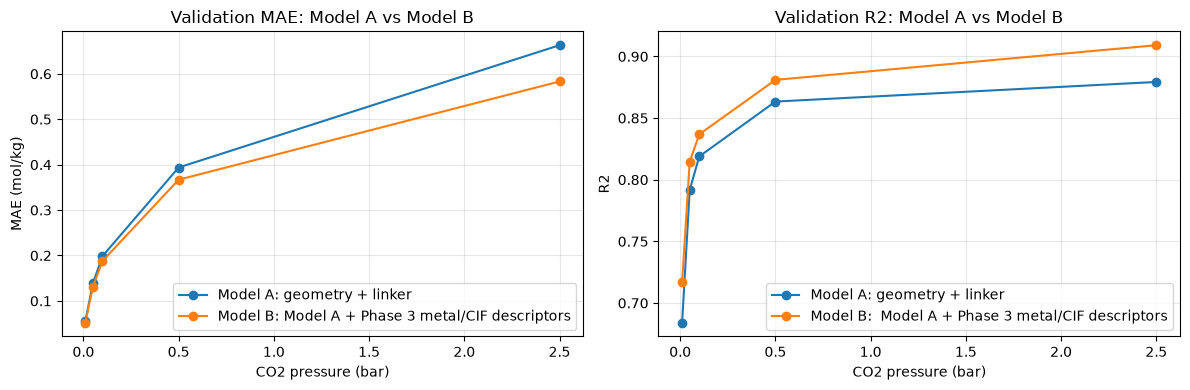

In [17]:
# Plot validation MAE and R2 for Model A and Model B across all CO2 pressures.

import matplotlib.pyplot as plt

pressures = [0.01, 0.05, 0.1, 0.5, 2.5]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Compare validation MAE.
axes[0].plot(
    pressures,
    results_model_a["valid_MAE"],
    marker="o",
    label="Model A: geometry + linker"
)

axes[0].plot(
    pressures,
    results_model_b["valid_MAE"],
    marker="o",
    label="Model B: Model A + Phase 3 metal/CIF descriptors"
)

axes[0].set_title("Validation MAE: Model A vs Model B")
axes[0].set_xlabel("CO2 pressure (bar)")
axes[0].set_ylabel("MAE (mol/kg)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Compare validation R2.
axes[1].plot(
    pressures,
    results_model_a["valid_R2"],
    marker="o",
    label="Model A: geometry + linker"
)

axes[1].plot(
    pressures,
    results_model_b["valid_R2"],
    marker="o",
    label="Model B:  Model A + Phase 3 metal/CIF descriptors"
)

axes[1].set_title("Validation R2: Model A vs Model B")
axes[1].set_xlabel("CO2 pressure (bar)")
axes[1].set_ylabel("R2")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

The Model A vs Model B plots compare validation performance across all five CO2 pressures. In the MAE plot, Model B has lower MAE than Model A at every pressure, meaning the predictions are more accurate after adding Phase 3 descriptors. In the R² plot, Model B has higher R² than Model A at every pressure, meaning the model explains more variation in CO2 uptake.

Because Model A and Model B use the same rows, same train/validation/test split, and same XGBoost settings, the improvement in Model B can be attributed to the added Phase 3 metal and CIF-derived structural descriptors.

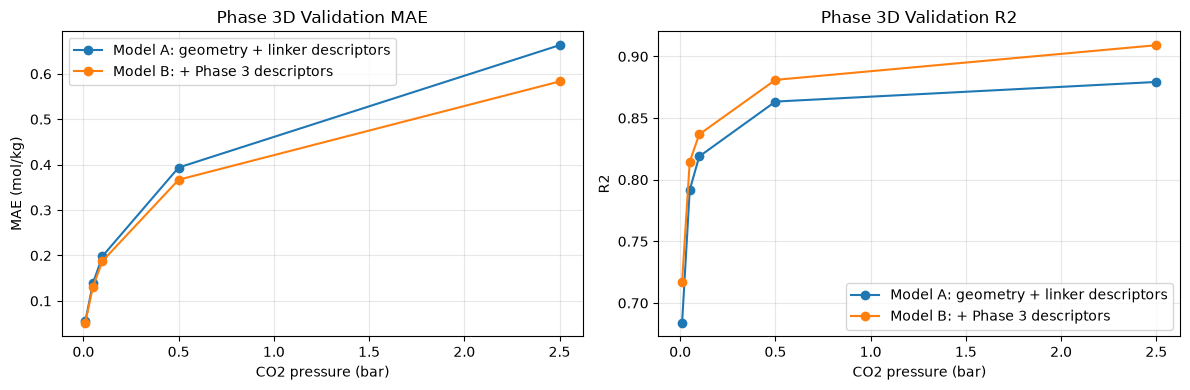

In [18]:
# Create separate panels for validation MAE and validation R2 for Phase 3D.
# Model A is the rebuilt Phase 2 baseline.
# Model B adds Phase 3 CIF-derived descriptors.

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Compare validation MAE; lower is better.
axes[0].plot(
    pressures,
    results_model_a["valid_MAE"],
    marker="o",
    label="Model A: geometry + linker descriptors"
)

axes[0].plot(
    pressures,
    results_model_b["valid_MAE"],
    marker="o",
    label="Model B: + Phase 3 descriptors"
)

axes[0].set_title("Phase 3D Validation MAE")
axes[0].set_xlabel("CO2 pressure (bar)")
axes[0].set_ylabel("MAE (mol/kg)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Compare validation R2; higher is better.
axes[1].plot(
    pressures,
    results_model_a["valid_R2"],
    marker="o",
    label="Model A: geometry + linker descriptors"
)

axes[1].plot(
    pressures,
    results_model_b["valid_R2"],
    marker="o",
    label="Model B: + Phase 3 descriptors"
)

axes[1].set_title("Phase 3D Validation R2")
axes[1].set_xlabel("CO2 pressure (bar)")
axes[1].set_ylabel("R2")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

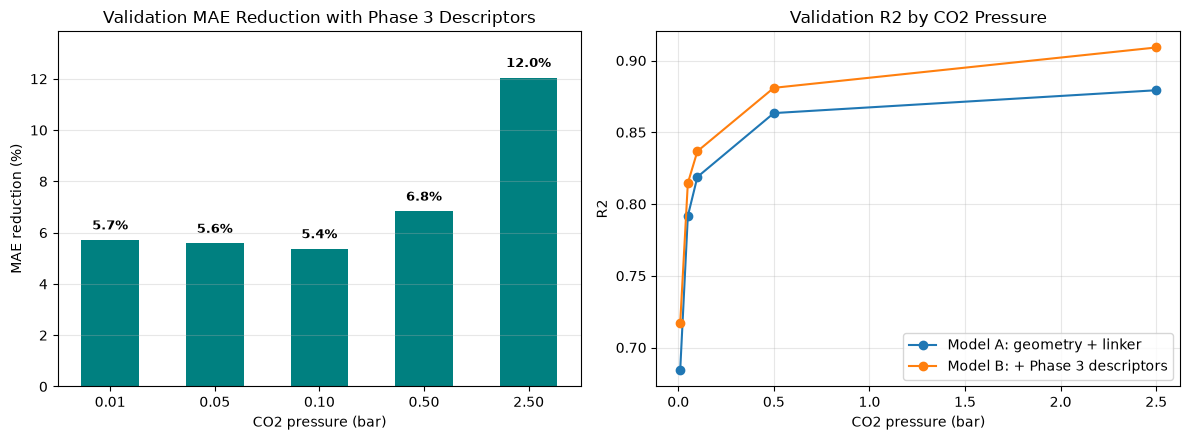

In [21]:
# Plot Phase 3D validation improvement from Model A to Model B.
# Left: MAE reduction percentage.
# Right: validation R2 comparison.

import matplotlib.pyplot as plt
import numpy as np

pressures_num = [0.01, 0.05, 0.1, 0.5, 2.5]
pressure_labels = ["0.01", "0.05", "0.10", "0.50", "2.50"]

mae_reduction_percent = (
    (results_model_a["valid_MAE"] - results_model_b["valid_MAE"])
    / results_model_a["valid_MAE"]
) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot MAE reduction as categorical bars.
bars = axes[0].bar(
    pressure_labels,
    mae_reduction_percent.values,
    color="teal",
    width=0.55
)

axes[0].set_title("Validation MAE Reduction with Phase 3 Descriptors")
axes[0].set_xlabel("CO2 pressure (bar)")
axes[0].set_ylabel("MAE reduction (%)")
axes[0].set_ylim(0, mae_reduction_percent.max() * 1.15)
axes[0].grid(axis="y", alpha=0.3)

# Add percent labels above bars.
for bar, value in zip(bars, mae_reduction_percent.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

# Plot validation R2 comparison.
axes[1].plot(
    pressures_num,
    results_model_a["valid_R2"],
    marker="o",
    label="Model A: geometry + linker"
)

axes[1].plot(
    pressures_num,
    results_model_b["valid_R2"],
    marker="o",
    label="Model B: + Phase 3 descriptors"
)

axes[1].set_title("Validation R2 by CO2 Pressure")
axes[1].set_xlabel("CO2 pressure (bar)")
axes[1].set_ylabel("R2")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Model Comparison: Phase 3D CIF-Derived Descriptors

#### Summary & Key Findings
* **Consistent Error Reduction:** Adding Phase 3 CIF-derived descriptors (Model B) reduces validation Mean Absolute Error (MAE) compared to Model A across all five tested $\text{CO}_2$ pressure levels ($0.01$ to $2.50\text{ bar}$).
* **Pressure Dependence:** MAE reduction remains steady at low-to-moderate pressures (**5.4% – 6.8%** from $0.01$ to $0.50\text{ bar}$) and peaks significantly at $2.50\text{ bar}$ (**12.0%** reduction).
* **Improved Variance Explanation:** Validation $R^2$ is consistently higher for Model B across the full pressure range, demonstrating enhanced explanatory power.

#### Conclusion
While geometry and linker descriptors establish a strong baseline, CIF-derived structural features (e.g., unit cell parameters, framework density, metal-node descriptors) provide crucial supplementary information that becomes increasingly vital for predicting high-pressure $\text{CO}_2$ adsorption.

In [25]:
# Define a reusable function to compute and plot SHAP feature importance
# for one model type across all CO2 pressure targets.
import shap
def compute_and_plot_shap(
    models_dict,
    X_train,
    X_valid,
    y_train_df,
    target_cols,
    sample_size=200,
    seed=SEED,
    model_name="Model"
):
    """
    Compute and plot SHAP values across multiple CO2 pressure targets.

    If models_dict is provided, the function uses the fitted models.
    If models_dict is None, the function fits a new XGBRegressor for each target.
    """

    # Sample the same validation rows for consistent SHAP calculation.
    sample_n = min(sample_size, len(X_valid))
    sample_index = X_valid.sample(
        n=sample_n,
        random_state=seed
    ).index

    X_shap = X_valid.loc[sample_index]

    shap_results = {}
    fitted_models = {}

    for target in target_cols:

        # Use an existing fitted model if available; otherwise fit a new model.
        if models_dict is not None and target in models_dict:
            model = models_dict[target]
        else:
            model = XGBRegressor(
                n_estimators=200,
                learning_rate=0.1,
                max_depth=3,
                min_child_weight=1,
                objective="reg:squarederror",
                random_state=seed,
                n_jobs=-1,
            )

            model.fit(X_train, y_train_df[target])

        fitted_models[target] = model

        # Calculate SHAP values for the sampled validation rows.
        explainer = shap.TreeExplainer(model)
        shap_values = explainer(X_shap)

        shap_results[target] = shap_values

        # Display SHAP bar plot.
        pressure_label = target.replace("CO2_uptake_", "").replace("_molkg", "")

        print(f"\n{model_name} SHAP feature importance | Pressure: {pressure_label}")
        shap.plots.bar(shap_values, max_display=15)

    return shap_results, X_shap, fitted_models

/home/susan/mof-co2-adsorption/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Model A: geometry + linker SHAP feature importance | Pressure: 0.01bar


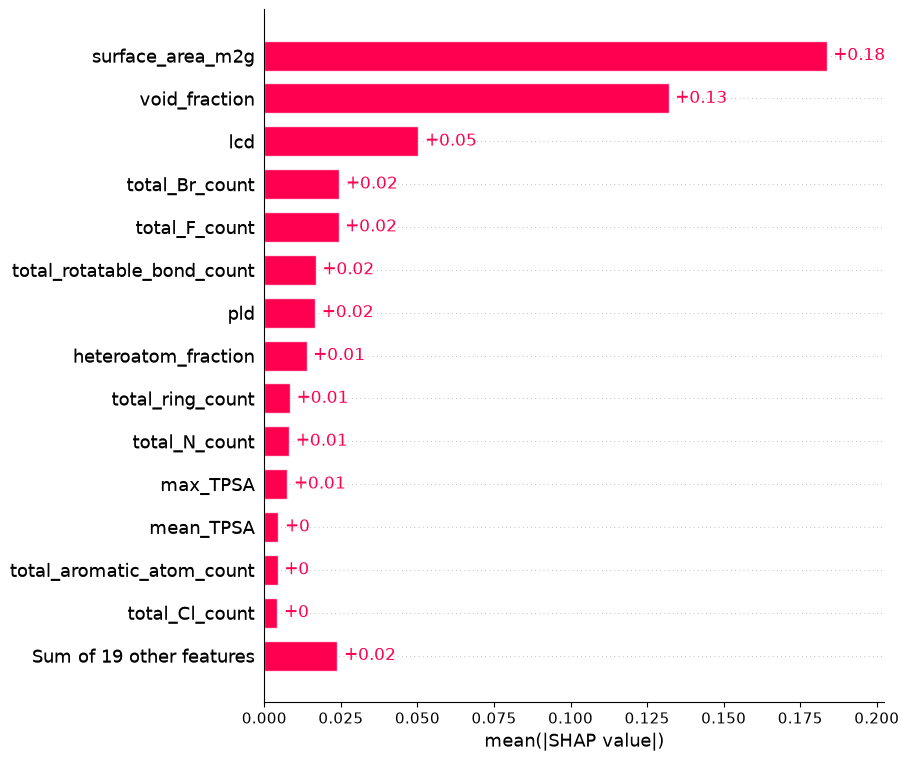


Model A: geometry + linker SHAP feature importance | Pressure: 0.05bar


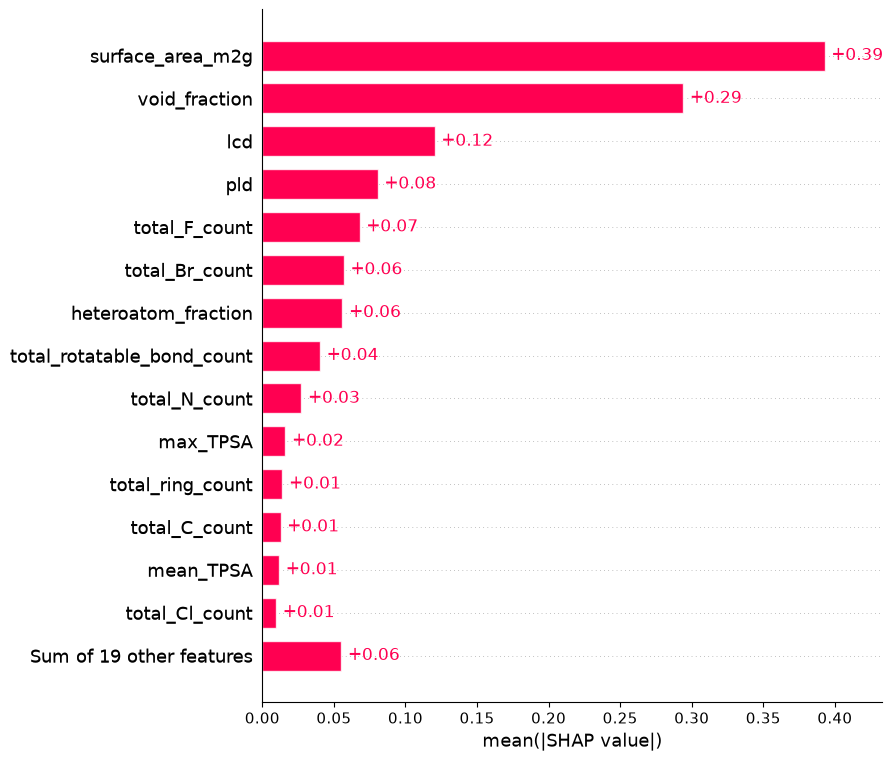


Model A: geometry + linker SHAP feature importance | Pressure: 0.1bar


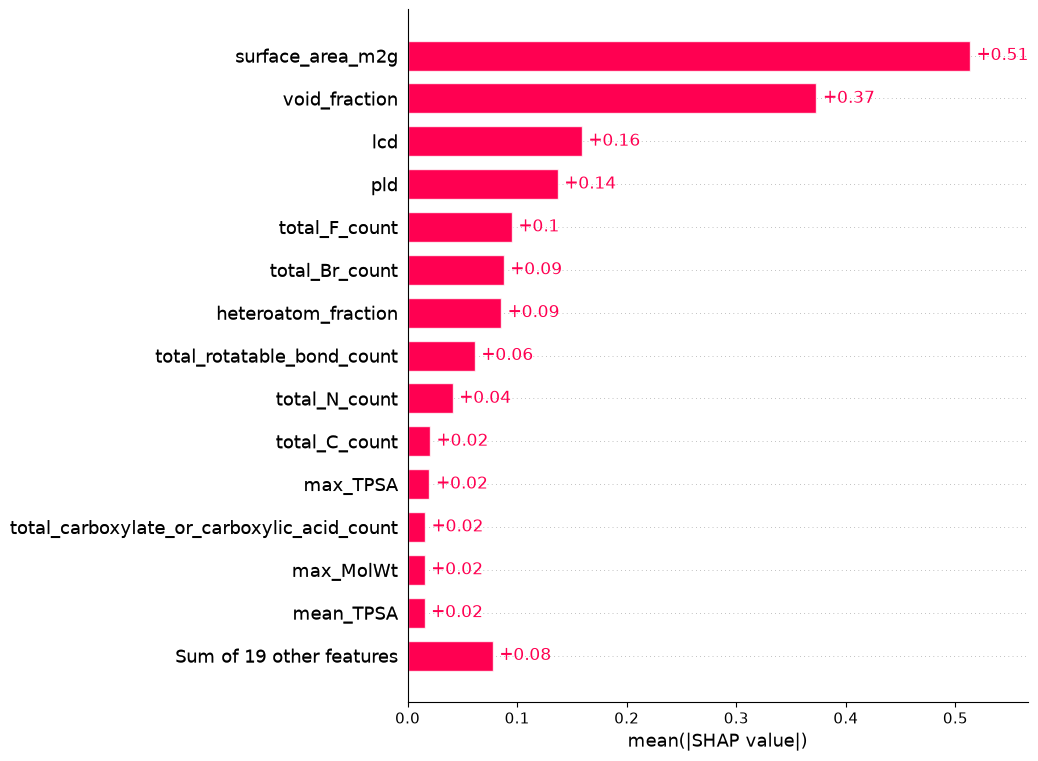


Model A: geometry + linker SHAP feature importance | Pressure: 0.5bar


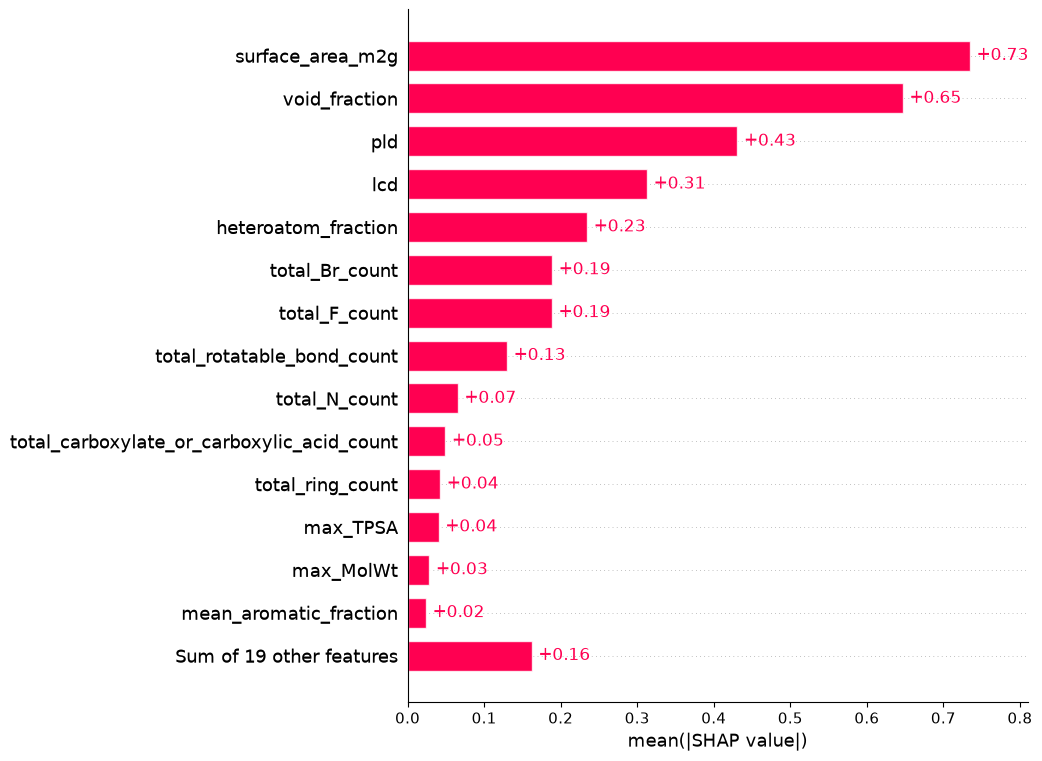


Model A: geometry + linker SHAP feature importance | Pressure: 2.5bar


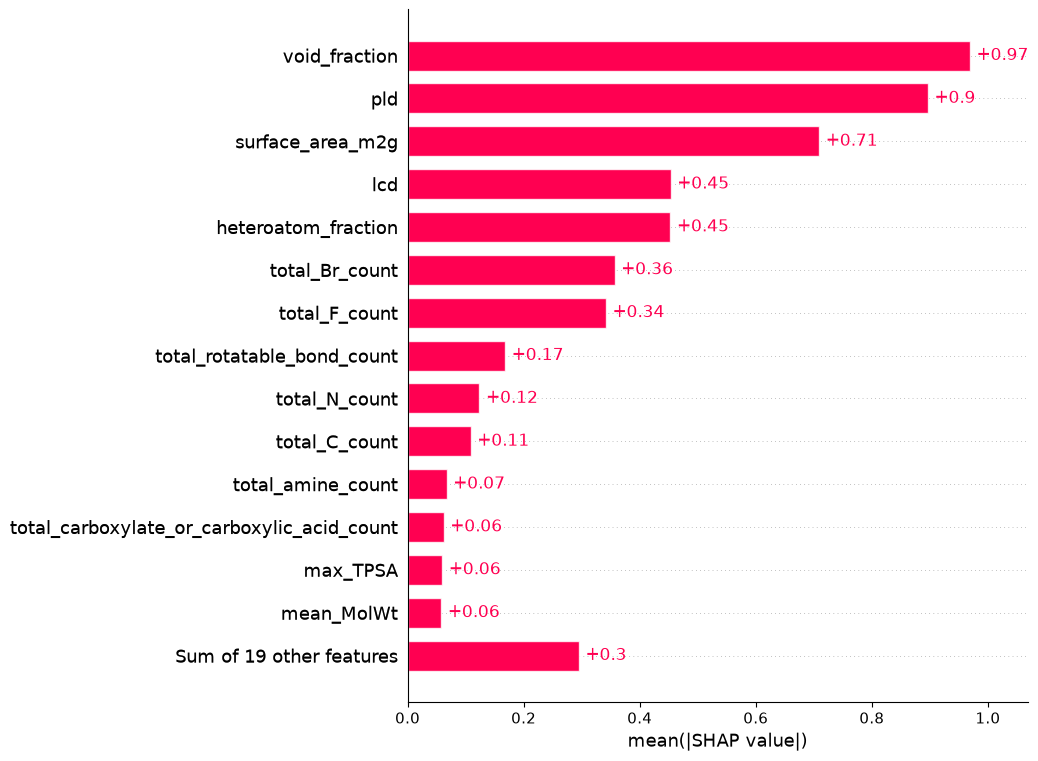

In [26]:
# Compute SHAP feature importance for Model A.
shap_results_a, X_shap_a, fitted_models_a = compute_and_plot_shap(
    models_dict=None,
    X_train=X_train_a,
    X_valid=X_valid_a,
    y_train_df=df_train,
    target_cols=target_cols,
    sample_size=200,
    seed=SEED,
    model_name="Model A: geometry + linker"
)

### Model A SHAP Feature Importance Across CO2 Pressures

* **Low pressure (0.01–0.10 bar):** SHAP feature importance is dominated by geometry features, especially surface area, void fraction, LCD, and PLD. Linker chemistry descriptors such as heteroatom fraction, fluorine count, bromine count, nitrogen count, and rotatable bond count also contribute, showing that linker composition adds predictive information beyond geometry.

* **Intermediate pressure (0.50 bar):** Surface area and void fraction remain highly important, while PLD becomes more influential. This suggests that both accessible surface and pore-size constraints affect CO2 uptake as pressure increases.

* **High pressure (2.50 bar):** Void fraction and PLD become the strongest predictors, followed by surface area and LCD. This indicates that high-pressure CO2 uptake is more strongly controlled by pore capacity and accessible pore size.

#### Summary & Transition
For Model A, SHAP analysis shows a pressure-dependent shift in feature importance. At lower pressures, surface area and void fraction dominate, with linker chemistry providing additional signal. At higher pressure, void fraction and PLD become more important, consistent with pore-filling behavior and adsorption capacity becoming dominant. However, Model A lacks global unit-cell and framework-level descriptors, which limits its ability to fully capture structural variance at elevated pressures—a gap addressed by Model B.


Model B: geometry + linker + Phase 3 descriptors SHAP feature importance | Pressure: 0.01bar


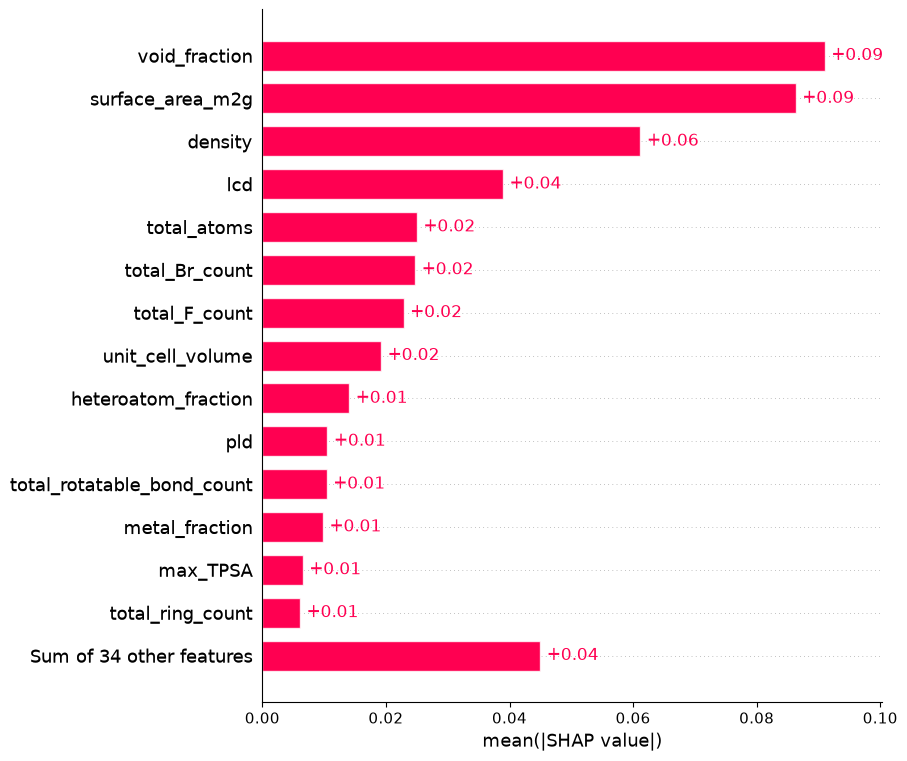


Model B: geometry + linker + Phase 3 descriptors SHAP feature importance | Pressure: 0.05bar


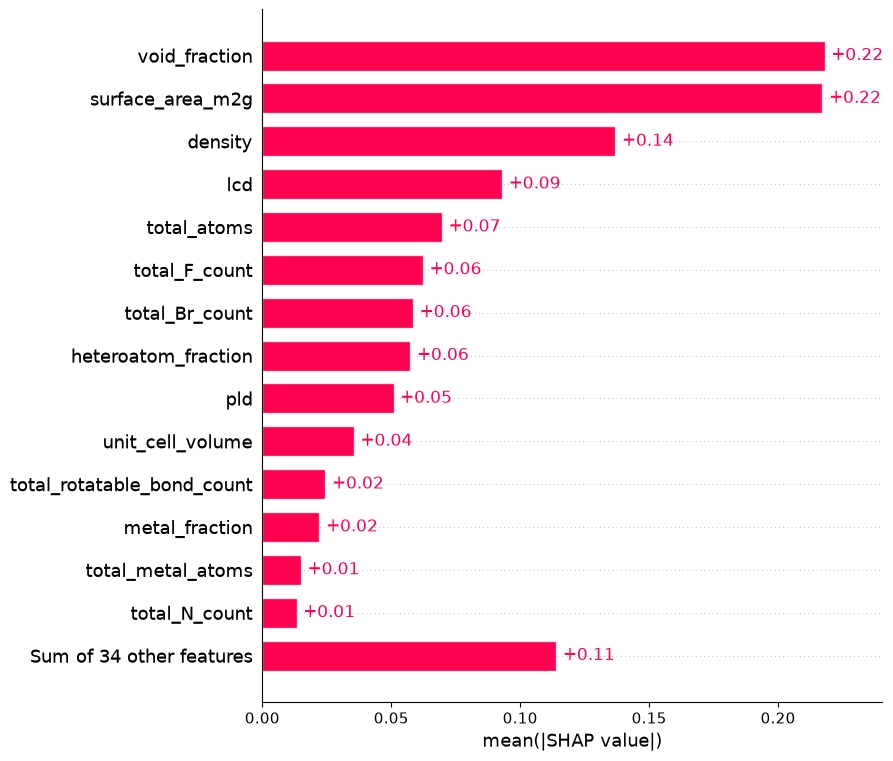


Model B: geometry + linker + Phase 3 descriptors SHAP feature importance | Pressure: 0.1bar


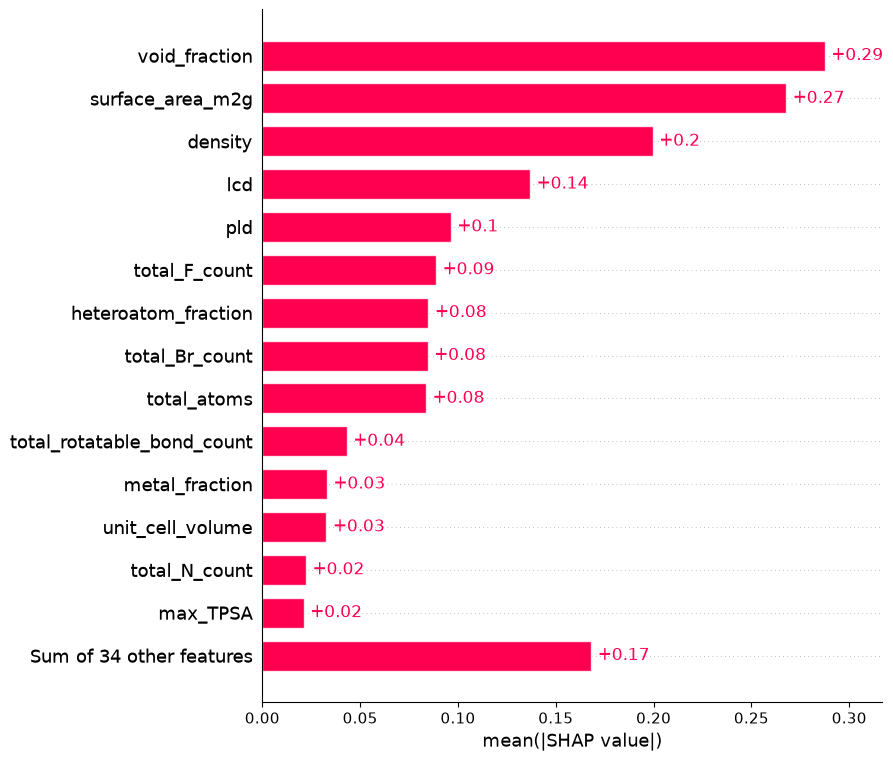


Model B: geometry + linker + Phase 3 descriptors SHAP feature importance | Pressure: 0.5bar


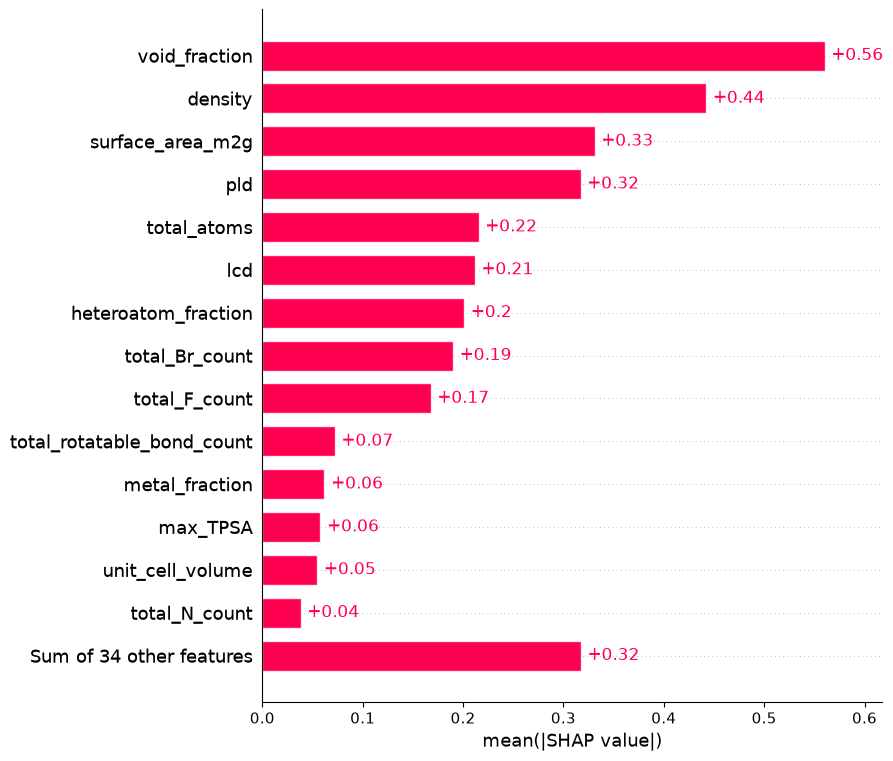


Model B: geometry + linker + Phase 3 descriptors SHAP feature importance | Pressure: 2.5bar


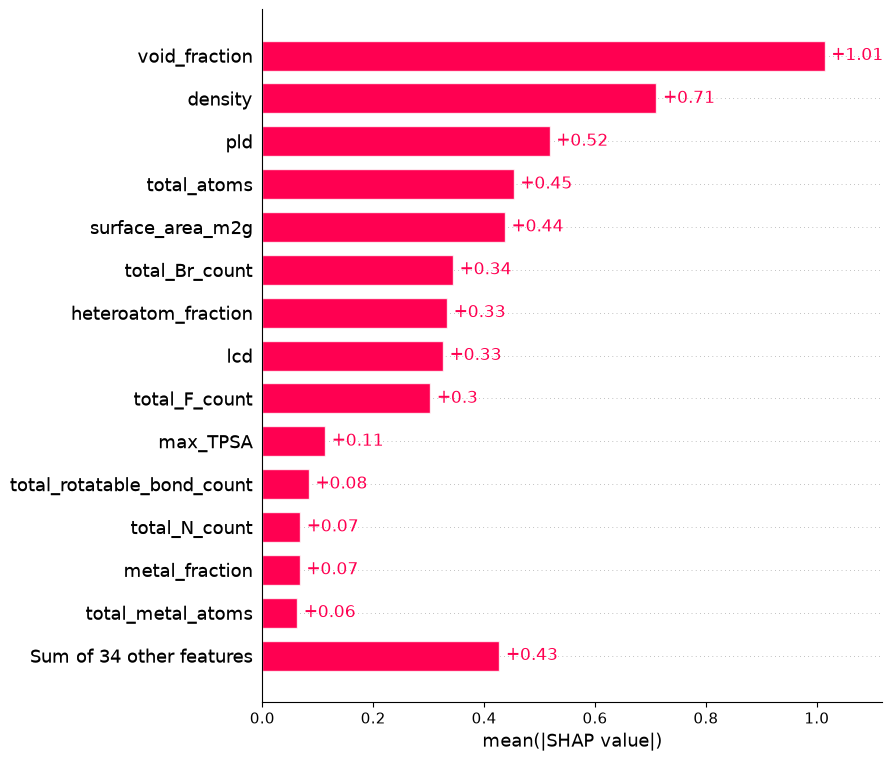

In [27]:
# Compute SHAP feature importance for Model B.
# Model B uses geometry + linker descriptors + Phase 3 CIF-derived descriptors.

shap_results_b, X_shap_b, fitted_models_b = compute_and_plot_shap(
    models_dict=None,
    X_train=X_train_b,
    X_valid=X_valid_b,
    y_train_df=df_train,
    target_cols=target_cols,
    sample_size=200,
    seed=SEED,
    model_name="Model B: geometry + linker + Phase 3 descriptors"
)

#### Conclusion for Model B

The introduction of Phase 3 CIF-derived descriptors in Model B fundamentally refines the model's predictive mechanism across all pressure regimes:

1. **Synergistic Low-Pressure Prediction:** At low pressures ($0.01\text{--}0.10\text{ bar}$), local surface geometry remains primary, but CIF descriptors immediately integrate to provide baseline structural context.
2. **High-Pressure Feature Emergence:** As pressure increases to $2.50\text{ bar}$, framework density (`density`) and unit-cell features surge into top-tier SHAP rankings. 
3. **Physical Validation:** This SHAP hierarchy shift directly explains the performance improvement of Model B over Model A—specifically the dramatic **12.0% MAE reduction at 2.50 bar**—confirming that global framework characteristics are indispensable for modeling high-density $CO_2$ uptake.

In [28]:
def get_top_shap_features(shap_results_dict, target_col, top_n=20):
    """Extract and rank mean absolute SHAP feature importance for one target pressure."""
    values = shap_results_dict[target_col]

    df_importance = pd.DataFrame(
        {
            "feature": values.feature_names,
            "mean_abs_SHAP": np.abs(values.values).mean(axis=0),
        }
    ).sort_values("mean_abs_SHAP", ascending=False)

    return df_importance.reset_index(drop=True).head(top_n)


# Select one pressure
target = "CO2_uptake_0.01bar_molkg"

# Get top features for Model A
top_features_a = get_top_shap_features(shap_results_a, target, top_n=20)
print(f"--- Model A Top 20 SHAP Features: {target} ---")
display(top_features_a)

# Get top features for Model B
top_features_b = get_top_shap_features(shap_results_b, target, top_n=20)
print(f"--- Model B Top 20 SHAP Features: {target} ---")
display(top_features_b)

--- Model A Top 20 SHAP Features: CO2_uptake_0.01bar_molkg ---


,feature,mean_abs_SHAP
0,surface_area_m2g,0.183634
1,void_fraction,0.132047
2,lcd,0.050311
3,total_Br_count,0.024485
4,total_F_count,0.024234
5,total_rotatable_bond_count,0.016793
6,pld,0.016599
7,heteroatom_fraction,0.013795
8,total_ring_count,0.008402
9,total_N_count,0.008129


--- Model B Top 20 SHAP Features: CO2_uptake_0.01bar_molkg ---


,feature,mean_abs_SHAP
0,void_fraction,0.091006
1,surface_area_m2g,0.086309
2,density,0.061166
3,lcd,0.038933
4,total_atoms,0.024996
5,total_Br_count,0.024721
6,total_F_count,0.022851
7,unit_cell_volume,0.019209
8,heteroatom_fraction,0.014048
9,pld,0.010511


### SHAP Interpretation at Low Pressure (0.01 bar)

1. **Geometry remains important, but its relative dominance decreases:**  
   In Model A, `surface_area_m2g` and `void_fraction` are the two strongest predictors. In Model B, these features remain highly important, but their mean absolute SHAP values decrease because the model now also uses additional CIF-derived descriptors.

2. **Phase 3 descriptors contribute at low pressure:**  
   In Model B, `density` becomes the #3 most important feature (`mean_abs_SHAP = 0.0612`). Other Phase 3 descriptors, including `total_atoms`, `unit_cell_volume`, `metal_fraction`, `total_metal_atoms`, `lattice_c`, and `lattice_alpha`, also appear in the top 20. This suggests that CIF-derived framework descriptors provide additional structural information beyond pore geometry and linker chemistry.

3. **Linker chemistry still contributes:**  
   Linker descriptors such as `total_Br_count`, `total_F_count`, `heteroatom_fraction`, and `total_rotatable_bond_count` remain among the important features in both models. This indicates that chemical composition still contributes to low-pressure CO2 uptake prediction even after adding Phase 3 descriptors.

In [32]:
# Create one summary table of the top SHAP features across all pressures
# for both Model A and Model B.

def summarize_top_shap_features(shap_results_dict, model_name, target_cols, top_n=10):
    """Create a table of top SHAP features for each target pressure."""
    summary_rows = []

    for target in target_cols:
        values = shap_results_dict[target]

        feature_importance = pd.DataFrame({
            "feature": values.feature_names,
            "mean_abs_SHAP": np.abs(values.values).mean(axis=0),
        })

        feature_importance = feature_importance.sort_values(
            "mean_abs_SHAP",
            ascending=False,
        ).head(top_n)

        pressure = (
            target
            .replace("CO2_uptake_", "")
            .replace("_molkg", "")
        )

        for rank, row in enumerate(feature_importance.itertuples(index=False), start=1):
            summary_rows.append({
                "model": model_name,
                "pressure": pressure,
                "rank": rank,
                "feature": row.feature,
                "mean_abs_SHAP": row.mean_abs_SHAP,
            })

    return pd.DataFrame(summary_rows)

In [33]:
# Display the full top SHAP feature summary table
display(top_shap_all)

# Print a short confirmation
print("Top SHAP features were summarized for all five pressures for Model A and Model B.")

,model,pressure,rank,feature,mean_abs_SHAP
0,Model A,0.01bar,1,surface_area_m2g,0.183634
1,Model A,0.01bar,2,void_fraction,0.132047
2,Model A,0.01bar,3,lcd,0.050311
3,Model A,0.01bar,4,total_Br_count,0.024485
4,Model A,0.01bar,5,total_F_count,0.024234
...,...,...,...,...,...
95,Model B,2.5bar,6,total_Br_count,0.343892
96,Model B,2.5bar,7,heteroatom_fraction,0.333264
97,Model B,2.5bar,8,lcd,0.325909
98,Model B,2.5bar,9,total_F_count,0.302909


Top SHAP features were summarized for all five pressures for Model A and Model B.


In [34]:
display(top_shap_all[top_shap_all["pressure"] == "0.01bar"])

,model,pressure,rank,feature,mean_abs_SHAP
0,Model A,0.01bar,1,surface_area_m2g,0.183634
1,Model A,0.01bar,2,void_fraction,0.132047
2,Model A,0.01bar,3,lcd,0.050311
3,Model A,0.01bar,4,total_Br_count,0.024485
4,Model A,0.01bar,5,total_F_count,0.024234
5,Model A,0.01bar,6,total_rotatable_bond_count,0.016793
6,Model A,0.01bar,7,pld,0.016599
7,Model A,0.01bar,8,heteroatom_fraction,0.013795
8,Model A,0.01bar,9,total_ring_count,0.008402
9,Model A,0.01bar,10,total_N_count,0.008129


In [35]:
# Create a table showing only the top SHAP feature
# for each pressure in Model A and Model B.

top_shap_a_1 = summarize_top_shap_features(
    shap_results_dict=shap_results_a,
    model_name="Model A",
    target_cols=target_cols,
    top_n=1,
)

top_shap_b_1 = summarize_top_shap_features(
    shap_results_dict=shap_results_b,
    model_name="Model B",
    target_cols=target_cols,
    top_n=1,
)

top_shap_1_all = pd.concat([top_shap_a_1, top_shap_b_1], ignore_index=True)

display(top_shap_1_all)

print("The top SHAP feature was identified for each pressure in Model A and Model B.")

,model,pressure,rank,feature,mean_abs_SHAP
0,Model A,0.01bar,1,surface_area_m2g,0.183634
1,Model A,0.05bar,1,surface_area_m2g,0.392875
2,Model A,0.1bar,1,surface_area_m2g,0.513268
3,Model A,0.5bar,1,surface_area_m2g,0.734674
4,Model A,2.5bar,1,void_fraction,0.969068
5,Model B,0.01bar,1,void_fraction,0.091006
6,Model B,0.05bar,1,void_fraction,0.218059
7,Model B,0.1bar,1,void_fraction,0.287438
8,Model B,0.5bar,1,void_fraction,0.560321
9,Model B,2.5bar,1,void_fraction,1.014173


The top SHAP feature was identified for each pressure in Model A and Model B.


### Comparison of Top-Ranked Features Across CO2 Pressures

* **Model A (baseline):** Model A shows a clear pressure-dependent transition. From 0.01 to 0.5 bar, `surface_area_m2g` is the top-ranked SHAP feature, with mean absolute SHAP values increasing from 0.1836 to 0.7347. This suggests that surface-mediated adsorption is the dominant signal at low-to-intermediate pressures. At 2.5 bar, `void_fraction` becomes the top feature (SHAP = 0.9691), consistent with high-pressure uptake being more controlled by pore-filling capacity.

* **Model B (+ Phase 3 CIF descriptors):** In Model B, `void_fraction` becomes the top-ranked feature at all five pressures, with SHAP values increasing from 0.0910 at 0.01 bar to 1.0142 at 2.5 bar. This suggests that after adding Phase 3 CIF-derived descriptors, the model places stronger emphasis on accessible void space across the full pressure range. The Phase 3 descriptors likely provide additional framework-level context, while `void_fraction` remains the dominant individual predictor.